# Portada

**UNIVERSIDAD AUTONOMA DEL ESTADO DE MEXICO (UAEMex)**

**Investigación de Operaciones**

**Ingeniería en Computación**

**ACTIVIDAD: Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook**

**Práctica: 3. Algoritmo de Dijkstra**

**Integrantes del equipo:**
 - David Alberto Ruiz Gonzalez
 - Alexia Guadalupe Sanchez Zamora

**Fecha:**: 18 noviembre de 2026

# Título del problema

**Ruta de menor latencia en una red de routers (Algoritmo de Dijkstra)**

## Descripción y planteamiento

Una red tiene **9 routers (R1–R9)** conectados por enlaces bidireccionales. Cada enlace tiene una **latencia en milisegundos**. Se desea enviar paquetes desde el router de origen **R1** hasta el servidor conectado en **R9** por el camino de **menor latencia total**.

### Formulación matemática

Sea $G=(V,E)$ un grafo no dirigido con pesos $c_{ij}\ge 0$ (latencias). Definimos $x_{ij}=1$ si el enlace $(i,j)$ se usa en el camino (en cualquier sentido):

$$\min \; Z=\sum_{(i,j)} c_{ij}\,x_{ij}$$

$$\text{s.a.}\quad \sum_{j} x_{sj}-\sum_{j} x_{js}=1,\qquad \sum_{j} x_{tj}-\sum_{j} x_{jt}=-1,\qquad \sum_{j} x_{kj}-\sum_{j} x_{jk}=0\;\;\forall k\neq s,t$$

con $s$ = R1 (origen) y $t$ = R9 (destino).

### Idea del algoritmo de Dijkstra

1. Asignar distancia $0$ al origen e $\infty$ a los demás.
2. Elegir el nodo **no visitado de menor distancia** y marcarlo como definitivo.
3. **Relajar** sus vecinos: si $d(u)+c_{uv}<d(v)$, actualizar $d(v)$ y su predecesor.
4. Repetir hasta que el destino quede definitivo.

Funciona porque todos los pesos son no negativos.

## Paso 1. Importación de bibliotecas

In [1]:
import heapq
import math
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


## Paso 2. Definición de datos

Cada tupla es `(router_a, router_b, latencia_ms)`.

In [2]:
enlaces = [
    ("R1", "R2", 7),  ("R1", "R3", 9),  ("R1", "R6", 14), ("R2", "R3", 10),
    ("R2", "R4", 15), ("R3", "R4", 11), ("R3", "R6", 2),  ("R4", "R5", 6),
    ("R5", "R6", 9),  ("R4", "R7", 8),  ("R5", "R8", 12), ("R6", "R8", 13),
    ("R7", "R8", 4),  ("R7", "R9", 9),  ("R8", "R9", 7),
]
ORIGEN, DESTINO = "R1", "R9"

G = nx.Graph()
G.add_weighted_edges_from(enlaces)

pos = {"R1": (0, 1.5), "R2": (2, 3), "R3": (2, 1.5), "R4": (4, 3), "R5": (5, 1.5),
       "R6": (3, 0), "R7": (6.5, 3), "R8": (6.5, 0.8), "R9": (8.5, 1.8)}

print(pd.DataFrame(enlaces, columns=["Router A", "Router B", "Latencia (ms)"]).to_string(index=False))
print("\nNodos:", G.number_of_nodes(), "| Enlaces:", G.number_of_edges())
print("Origen:", ORIGEN, "| Destino:", DESTINO)

Router A Router B  Latencia (ms)
      R1       R2              7
      R1       R3              9
      R1       R6             14
      R2       R3             10
      R2       R4             15
      R3       R4             11
      R3       R6              2
      R4       R5              6
      R5       R6              9
      R4       R7              8
      R5       R8             12
      R6       R8             13
      R7       R8              4
      R7       R9              9
      R8       R9              7

Nodos: 9 | Enlaces: 15
Origen: R1 | Destino: R9


## Paso 3. Función de dibujo y gráfica de la red original

Código de colores: **rojo** = nodo que se acaba de fijar, **verde** = distancia definitiva, **naranja** = distancia provisional (frontera), **gris** = aún no alcanzado. Las aristas verdes forman el árbol de caminos más cortos encontrado hasta el momento.

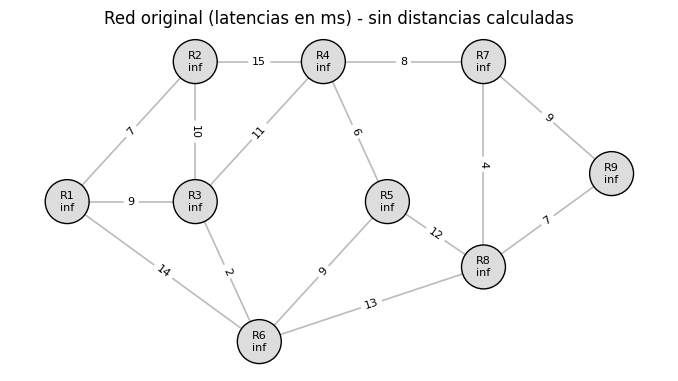

In [3]:
def dibujar(dist, visitados, actual=None, prev=None, camino=None, titulo=""):
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    colores = []
    for n in G.nodes():
        if n == actual:
            colores.append("#ff6b6b")
        elif n in visitados:
            colores.append("#8fd694")
        elif dist[n] < math.inf:
            colores.append("#ffc069")
        else:
            colores.append("#dddddd")

    nx.draw_networkx_edges(G, pos, edge_color="#bbbbbb", width=1.2, ax=ax)
    if prev:
        arbol = [(v, p) for v, p in prev.items() if p]
        nx.draw_networkx_edges(G, pos, edgelist=arbol, edge_color="green", width=3, ax=ax)
    if camino:
        tramos = list(zip(camino[:-1], camino[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=tramos, edge_color="red", width=5, ax=ax)

    nx.draw_networkx_nodes(G, pos, node_color=colores, node_size=1000,
                           edgecolors="black", ax=ax)
    etiquetas = {n: f"{n}\n{'inf' if dist[n] == math.inf else dist[n]}" for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, etiquetas, font_size=8, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "weight"),
                                 font_size=8, ax=ax)
    ax.set_title(titulo)
    ax.axis("off")
    plt.show()


dist0 = {n: math.inf for n in G.nodes()}
dibujar(dist0, set(), titulo="Red original (latencias en ms) - sin distancias calculadas")

## Paso 4. Inicialización

$d(R1)=0$, $d(v)=\infty$ para el resto, sin predecesores. Se usa una **cola de prioridad** (`heapq`) para extraer siempre el nodo de menor distancia.

Distancias iniciales: {'R1': 0, 'R2': 'inf', 'R3': 'inf', 'R6': 'inf', 'R4': 'inf', 'R5': 'inf', 'R7': 'inf', 'R8': 'inf', 'R9': 'inf'}


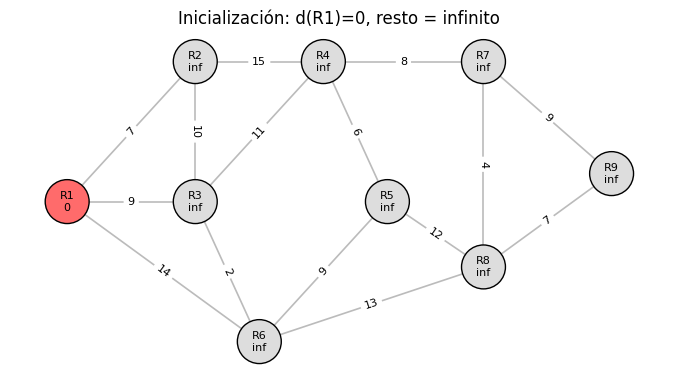

In [16]:
dist = {n: math.inf for n in G.nodes()}
prev = {n: None for n in G.nodes()}
dist[ORIGEN] = 0
cola = [(0, ORIGEN)]
visitados = []

print("Distancias iniciales:", {n: ("inf" if d == math.inf else d) for n, d in dist.items()})
dibujar(dist, set(), actual=ORIGEN, prev=prev, titulo="Inicialización: d(R1)=0, resto = infinito")

## Paso 5. Ejecución paso a paso

En cada iteración: (1) se extrae el nodo con menor distancia y se **fija**; (2) se **relajan** sus vecinos; (3) se muestra la tabla de distancias y se grafica el estado.

Iteración 1: se fija R1 con distancia definitiva 0 ms
   Relajar R1->R2: 0 + 7 = 7 < inf  => actualiza
   Relajar R1->R3: 0 + 9 = 9 < inf  => actualiza
   Relajar R1->R6: 0 + 14 = 14 < inf  => actualiza
                    R1                        R2                        R3                        R6                        R4                        R5                        R7                        R8                        R9
Distancia            0                         7                         9                        14                       inf                       inf                       inf                       inf                       inf
Predecesor           -                        R1                        R1                        R1                         -                         -                         -                         -                         -
Estado      definitivo  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  pr

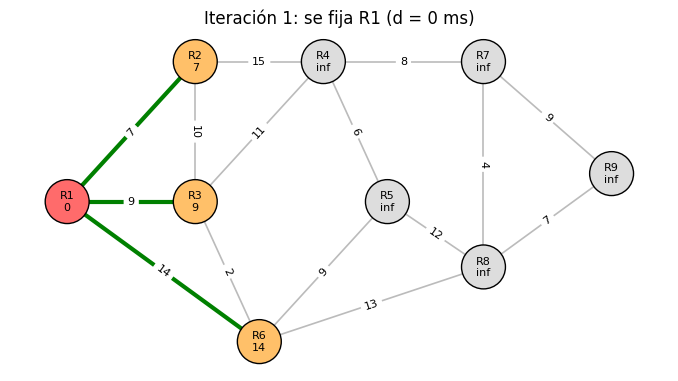

Iteración 2: se fija R2 con distancia definitiva 7 ms
   Relajar R2->R3: 7 + 10 = 17 >= 9  => sin cambio
   Relajar R2->R4: 7 + 15 = 22 < inf  => actualiza
                    R1          R2                        R3                        R6                        R4                        R5                        R7                        R8                        R9
Distancia            0           7                         9                        14                        22                       inf                       inf                       inf                       inf
Predecesor           -          R1                        R1                        R1                        R2                         -                         -                         -                         -
Estado      definitivo  definitivo  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  p

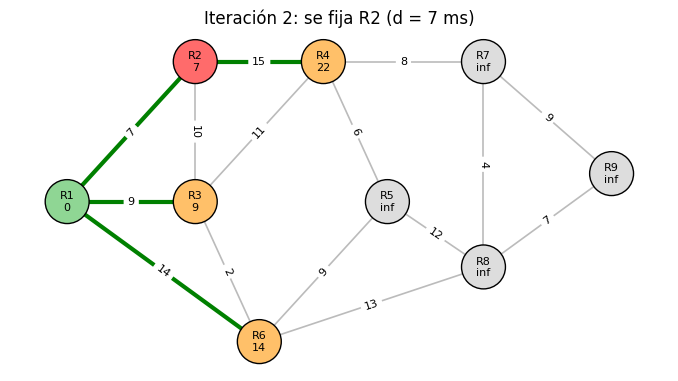

Iteración 3: se fija R3 con distancia definitiva 9 ms
   Relajar R3->R4: 9 + 11 = 20 < 22  => actualiza
   Relajar R3->R6: 9 + 2 = 11 < 14  => actualiza
                    R1          R2          R3                        R6                        R4                        R5                        R7                        R8                        R9
Distancia            0           7           9                        11                        20                       inf                       inf                       inf                       inf
Predecesor           -          R1          R1                        R3                        R3                         -                         -                         -                         -
Estado      definitivo  definitivo  definitivo  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado


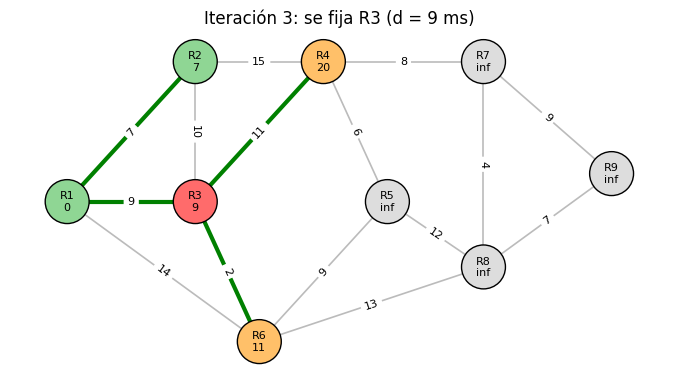

Iteración 4: se fija R6 con distancia definitiva 11 ms
   Relajar R6->R5: 11 + 9 = 20 < inf  => actualiza
   Relajar R6->R8: 11 + 13 = 24 < inf  => actualiza
                    R1          R2          R3          R6                        R4                        R5                        R7                        R8                        R9
Distancia            0           7           9          11                        20                        20                       inf                        24                       inf
Predecesor           -          R1          R1          R3                        R3                        R6                         -                        R6                         -
Estado      definitivo  definitivo  definitivo  definitivo  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado


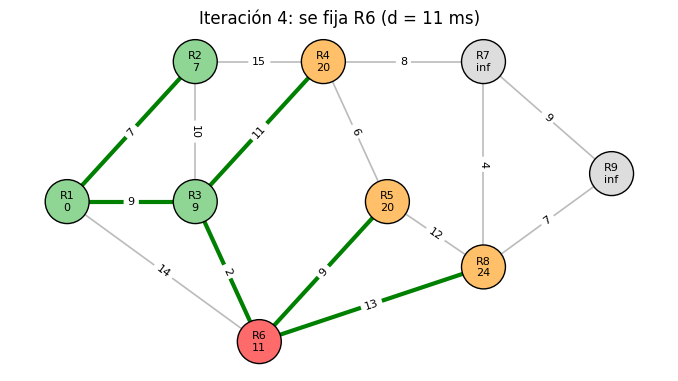

Iteración 5: se fija R4 con distancia definitiva 20 ms
   Relajar R4->R5: 20 + 6 = 26 >= 20  => sin cambio
   Relajar R4->R7: 20 + 8 = 28 < inf  => actualiza
                    R1          R2          R3          R6          R4                        R5                        R7                        R8                        R9
Distancia            0           7           9          11          20                        20                        28                        24                       inf
Predecesor           -          R1          R1          R3          R3                        R6                        R4                        R6                         -
Estado      definitivo  definitivo  definitivo  definitivo  definitivo  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado


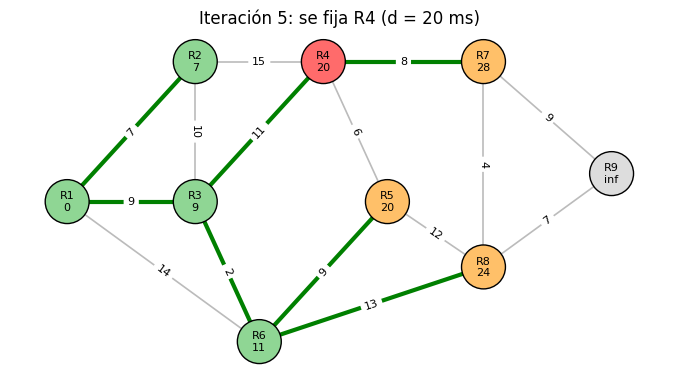

Iteración 6: se fija R5 con distancia definitiva 20 ms
   Relajar R5->R8: 20 + 12 = 32 >= 24  => sin cambio
                    R1          R2          R3          R6          R4          R5                        R7                        R8                        R9
Distancia            0           7           9          11          20          20                        28                        24                       inf
Predecesor           -          R1          R1          R3          R3          R6                        R4                        R6                         -
Estado      definitivo  definitivo  definitivo  definitivo  definitivo  definitivo  provisional/no alcanzado  provisional/no alcanzado  provisional/no alcanzado


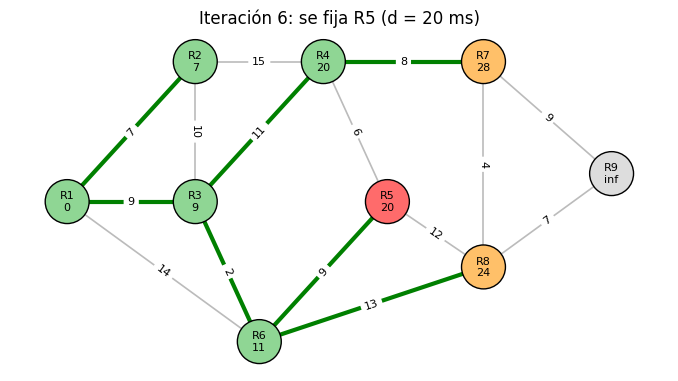

Iteración 7: se fija R8 con distancia definitiva 24 ms
   Relajar R8->R7: 24 + 4 = 28 >= 28  => sin cambio
   Relajar R8->R9: 24 + 7 = 31 < inf  => actualiza
                    R1          R2          R3          R6          R4          R5                        R7          R8                        R9
Distancia            0           7           9          11          20          20                        28          24                        31
Predecesor           -          R1          R1          R3          R3          R6                        R4          R6                        R8
Estado      definitivo  definitivo  definitivo  definitivo  definitivo  definitivo  provisional/no alcanzado  definitivo  provisional/no alcanzado


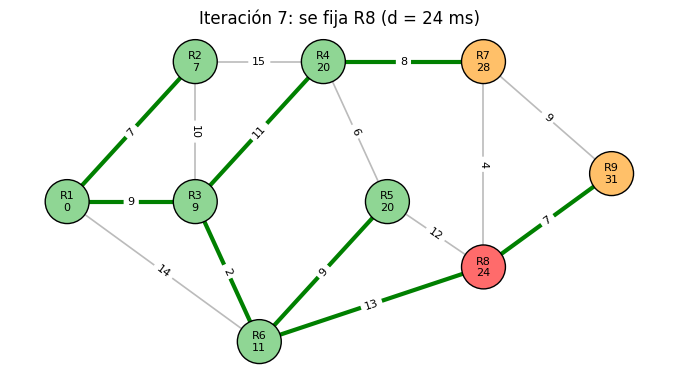

Iteración 8: se fija R7 con distancia definitiva 28 ms
   Relajar R7->R9: 28 + 9 = 37 >= 31  => sin cambio
                    R1          R2          R3          R6          R4          R5          R7          R8                        R9
Distancia            0           7           9          11          20          20          28          24                        31
Predecesor           -          R1          R1          R3          R3          R6          R4          R6                        R8
Estado      definitivo  definitivo  definitivo  definitivo  definitivo  definitivo  definitivo  definitivo  provisional/no alcanzado


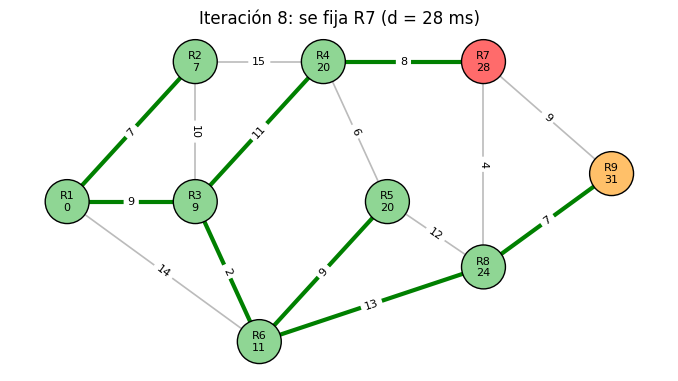

Iteración 9: se fija R9 con distancia definitiva 31 ms
                    R1          R2          R3          R6          R4          R5          R7          R8          R9
Distancia            0           7           9          11          20          20          28          24          31
Predecesor           -          R1          R1          R3          R3          R6          R4          R6          R8
Estado      definitivo  definitivo  definitivo  definitivo  definitivo  definitivo  definitivo  definitivo  definitivo


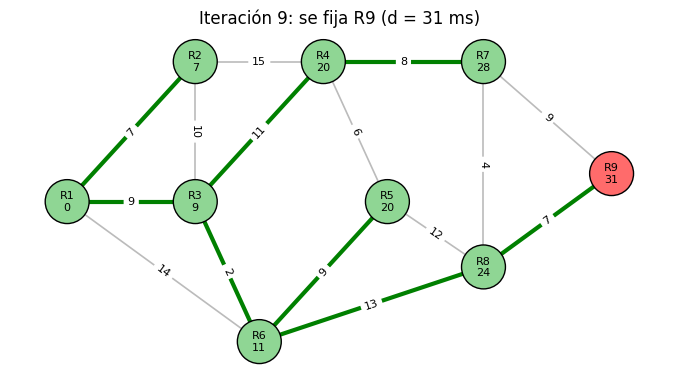


El destino quedó fijado: el algoritmo termina.


In [17]:
iteracion = 0
while cola:
    d, u = heapq.heappop(cola)
    if u in visitados:
        continue
    visitados.append(u)
    iteracion += 1
    print("=" * 62)
    print(f"Iteración {iteracion}: se fija {u} con distancia definitiva {d} ms")

    for v in G.neighbors(u):
        if v in visitados:
            continue
        nuevo = d + G[u][v]["weight"]
        if nuevo < dist[v]:
            antes = "inf" if dist[v] == math.inf else dist[v]
            dist[v], prev[v] = nuevo, u
            heapq.heappush(cola, (nuevo, v))
            print(f"   Relajar {u}->{v}: {d} + {G[u][v]['weight']} = {nuevo} < {antes}  => actualiza")
        else:
            print(f"   Relajar {u}->{v}: {d} + {G[u][v]['weight']} = {nuevo} >= {dist[v]}  => sin cambio")

    estado = pd.DataFrame({
        "Distancia": ["inf" if x == math.inf else x for x in dist.values()],
        "Predecesor": [prev[n] or "-" for n in dist],
        "Estado": ["definitivo" if n in visitados else "provisional/no alcanzado" for n in dist],
    }, index=list(dist))
    print(estado.T.to_string())

    dibujar(dist, set(visitados), actual=u, prev=prev,
            titulo=f"Iteración {iteracion}: se fija {u} (d = {d} ms)")

    if u == DESTINO:
        print("\nEl destino quedó fijado: el algoritmo termina.")
        break

## Paso 6. Reconstrucción de la ruta más corta y distancia total

In [8]:
camino = []
nodo = DESTINO
while nodo is not None:
    camino.append(nodo)
    nodo = prev[nodo]
camino.reverse()

print("Ruta más corta :", " -> ".join(camino))
print("Distancia total:", dist[DESTINO], "ms")
print()
tramos = pd.DataFrame(
    [(a, b, G[a][b]["weight"]) for a, b in zip(camino[:-1], camino[1:])],
    columns=["De", "A", "Latencia (ms)"])
tramos["Acumulado (ms)"] = tramos["Latencia (ms)"].cumsum()
print(tramos.to_string(index=False))

Ruta más corta : R1 -> R3 -> R6 -> R8 -> R9
Distancia total: 31 ms

De  A  Latencia (ms)  Acumulado (ms)
R1 R3              9               9
R3 R6              2              11
R6 R8             13              24
R8 R9              7              31


## Paso 7. Visualización de la solución

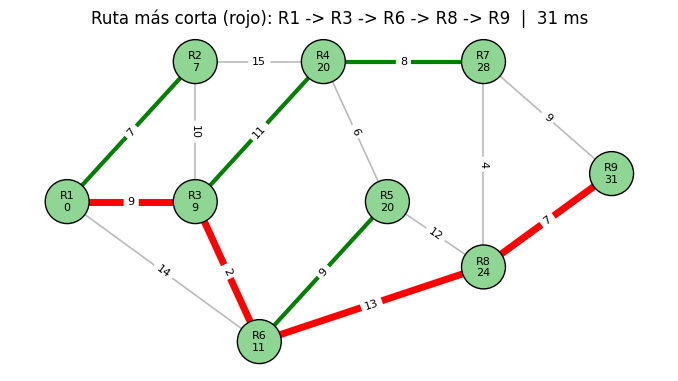

In [9]:
dibujar(dist, set(visitados), prev=prev, camino=camino,
        titulo=f"Ruta más corta (rojo): {' -> '.join(camino)}  |  {dist[DESTINO]} ms")

## Paso 8. Justificación de los resultados

Comprobamos que ninguna ruta alternativa es mejor: enumeramos todas las rutas simples de R1 a R9, las ordenamos por latencia y comparamos con NetworkX.

In [10]:
rutas = []
for r in nx.all_simple_paths(G, ORIGEN, DESTINO):
    costo = sum(G[a][b]["weight"] for a, b in zip(r[:-1], r[1:]))
    rutas.append((costo, " -> ".join(r)))
rutas.sort()

print(f"Rutas simples existentes entre {ORIGEN} y {DESTINO}: {len(rutas)}")
print("\nLas 5 mejores:")
for costo, r in rutas[:5]:
    print(f"  {costo:3d} ms   {r}")

nx_ruta = nx.dijkstra_path(G, ORIGEN, DESTINO)
nx_dist = nx.dijkstra_path_length(G, ORIGEN, DESTINO)
print("\nNetworkX:", " -> ".join(nx_ruta), "|", nx_dist, "ms")
print("¿Coincide con la implementación propia?:", nx_ruta == camino and nx_dist == dist[DESTINO])
print("¿Es la mínima entre todas las rutas?:", rutas[0][0] == dist[DESTINO])

Rutas simples existentes entre R1 y R9: 57

Las 5 mejores:
   31 ms   R1 -> R3 -> R6 -> R8 -> R9
   34 ms   R1 -> R6 -> R8 -> R9
   37 ms   R1 -> R3 -> R4 -> R7 -> R9
   37 ms   R1 -> R3 -> R6 -> R8 -> R7 -> R9
   39 ms   R1 -> R2 -> R3 -> R6 -> R8 -> R9

NetworkX: R1 -> R3 -> R6 -> R8 -> R9 | 31 ms
¿Coincide con la implementación propia?: True
¿Es la mínima entre todas las rutas?: True


# Interpretación de resultados

- La ruta de menor latencia de R1 a R9 es **R1 → R3 → R6 → R8 → R9**, con una **latencia total de 31 ms**.
- Aunque el enlace directo R1–R6 existe, cuesta 14 ms; rodear por R3 (9 + 2 = 11 ms) es más barato. Dijkstra lo detecta al **relajar** R6 desde R3 y reemplazar la distancia provisional de 14 por 11.
- Las rutas alternativas (por ejemplo, vía R4 y R7) tienen mayor latencia; la enumeración exhaustiva y NetworkX confirman que 31 ms es el mínimo.
- Cada nodo se fija **una sola vez** y su distancia ya no cambia: esto garantiza la optimalidad cuando no hay pesos negativos.
- Complejidad con cola de prioridad: $O((|V|+|E|)\log|V|)$, eficiente incluso en redes grandes.

## Aplicación al área de Tecnologías de la Información

- **Protocolos de enrutamiento de estado de enlace (OSPF, IS-IS):** cada router ejecuta Dijkstra sobre su base de datos de enlaces para construir su tabla de rutas.
- **Optimización de latencia** en CDN, balanceo de carga y microservicios.
- **Sistemas de navegación y mapas**, redes de transporte y logística.
- **Redes de comunicaciones y videojuegos** (pathfinding), y análisis de grafos en redes sociales.

## Conclusiones del equipo


El algoritmo de Dijkstra encontró la ruta R1-R3-R6-R8-R9 con una latencia de 31 ms, resultado que coincide con NetworkX y con la enumeración de todas las rutas posibles. Ver cómo se fijan los nodos uno a uno y cómo se actualizan las distancias provisionales ayudó a entender el concepto de relajación de aristas. Es la base de protocolos reales como OSPF.


## Conclusiones individuales

| Integrante | Conclusión individual |
|---|---|
| Conclusion (DAvid Alberto)| Este algoritmo nos puede ayudar a tener mayores eficacias dentro de una red de transporte o como en este caso, mayor velocidad en los enrutamientos, esto nos lleva a mayor optimizacion en produccion y mas eficacia dentro de lo que querramos optimizar|
| Conclusion (Alexia Guadalupe) |Con esta práctica aprendí cómo funciona el algoritmo de Dijkstra para encontrar la ruta más corta entre dos puntos de una red. También comprendí cómo se van actualizando las distancias hasta encontrar el camino con menor latencia. Esta actividad me ayudó a entender cómo se puede aplicar este algoritmo en las redes de computadoras para mejorar la comunicación y reducir los tiempos de transmisión. |
